# Defining the Game: Tic-Tac-Toe

## The Search Problem

A general search problem is defined in the following way:

* **Initial State:** Empty $3 \times 3$ board. It is the move for $x$.
* **Actions:** Place your symbol on any empty square.
* **Transition function:** You symbol is placed on the board according to the action. The opponent
    places her symbol. From our viewpoint this makes the environment non-deterministic.
* **Goal state:** A win (three symbols in a row, column or diagonal). 
* **Path cost:** number of moves.
  
Since Tic-tac-toe is a game, we will use the more specializes components (see Chapter 5):
* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

**Notes:**

* To define the goal state we will use a test for a **terminal state** (game is over) and a **utility function** (win or loose). 
* We will use DFS which is not optimal. So will probably not find the solution with the lowest path cost, i.e., win with the smallest number of moves. Therefore, we drop the path cost all together.

## Problem Size

### State Space Estimates

Each state is a possible board. Each of the 9 squares can have 3 values (empty, x and o), but some boards are impossible (where a player has several sequences of 3).The number of states in the state space graph is less than $3^9$.

In [ ]:
3**9

19683

A tighter bound for the search space size would be looking at all the ways we can choose $i = 1,2,3,...,9$ places from the board given by ${9 \choose i}$. Now we need to find all ways how we can choose half the symbols for player o which is given by ${i \choose \lfloor \frac{i}{2} \rfloor}$. 
Put together we get $\sum_{i=1}^9{{9 \choose i}{i \choose \lfloor \frac{i}{2} \rfloor}}$.

In [ ]:
import math

print("level\tboards")
total_states = 0

for i in range(1,9):
    total_states += math.comb(9, i) * math.comb(i, math.floor(i/2))
    print(i, "\t", math.comb(9, i) , " x ", math.comb(i, math.floor(i/2)) , " = ",  math.comb(9, i) * math.comb(i, math.floor(i/2)))

total_states

level	boards
1 	 9  x  1  =  9
2 	 36  x  2  =  72
3 	 84  x  3  =  252
4 	 126  x  6  =  756
5 	 126  x  10  =  1260
6 	 84  x  20  =  1680
7 	 36  x  35  =  1260
8 	 9  x  70  =  630


5919

This is an upper bound since it contains some infeasible boards where both players have 3 in a row.

### Space and Time Complexity Using the Search Tree Estimates

For solving the problem, we use the search tree which can be significantly larger than the state space.
A search tree is a subgraph with all **cycles removed.** The standard implementation of DFS **cannot remove redundant paths** (i.e., getting to the same board by plcing symbols in a different order). Therefore, a state can be represented by several nodes in different branches! We observe the following:

* The complete search tree has a maximal depth $m=9$
* The max branching factor $b=9$ (for first move).

DFS has

* a space complexity of $O(bm)$ (current path plus frontier) and 
* a time complecity of $O(b^m)$ (number of expanded nodes).

In [ ]:
# Space Complexity O(bm):
9*9

81

In [ ]:
# Time Complexity O(b^m): 
9**9

387420489

The branching factor decreases after each move. The first level has a branching factor of 9, the second a branching factor of 8, etc. The total number of nodes is:

| <div style="width:100px">Level</div>      |  <div style="width:200px"># of nodes</div>   |
| :------------- | :---------------- |
| root       | $1$ |
| level 1    | $9 = 9!/8!$ |
| level 2    | $9 \times 8 = 9!/7!$ |
| level 2    | $9 \times 8 \times 7 = 9!/6!$ |
| ...        |  ... |
| level 9    | $9 \times 8 \times \dots \times 2 \times 1 = 9!$ |

The total number of game tree nodes is less (some games end early) than the sum of the nodes above. The upper bound for the number of nodes is

$\sum_{i = 0}^9 \frac{9!}{i!}$

In [ ]:
total_nodes = 1
partial_fac = 1
print("level\t# nodes")
print("root\t 1")

for i in range(9, 0, -1):
    partial_fac *= i
    total_nodes += partial_fac 
    print(10-i, "\t", partial_fac)
    
total_nodes

level	# nodes
root	 1
1 	 9
2 	 72
3 	 504
4 	 3024
5 	 15120
6 	 60480
7 	 181440
8 	 362880
9 	 362880


986410

Since some sequences are cut short because of a win, we expect fewer nodes in the game complete tree.

**Redundant paths:** The tree size estimation contains redundant paths.

**Cycles:** Tic-tac-toe does not have cycles (you cannot remove a played symbol).


__Note:__ This size makes tic-tac-toe a very small problem that can be easily solved by tree search. Most games and real problems are too large and cannot be solved this way. For example, chess has an estimated state space size of $>10^{30}$. 
We will learn several methods that address this problem later.

## Implementation

We need to implement the following functions:

* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

The state (a board position) will be implemented as a vector (in Python this is a list) of length 9. The values are `' ', 'x', 'o'`. The actions are just the index in the list (0, 1, 2, ..., 8).


The implementation of these and some other helper functions can be found in [tictactoe.py](tictactoe.py)
and be imported from that file

In [ ]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [ ]:
from tictactoe import empty_board, actions, result, terminal, utility, check_board
from tictactoe import show_board, show_board_text

## Examples

The board is a row-major vector: positions `0, 1, 2` are the top row, `3, 4, 5` the middle row, and `6, 7, 8` the bottom row. Thus position `4` is the center.

- `empty_board()` returns nine blank cells; `actions(s)` returns the indices of blank cells.
- `result(s, player, action)` returns a **new** board and rejects occupied/out-of-range actions.
- `terminal(s)` delegates to `check_board(s)`, which returns `x`, `o`, `d` (draw), or `n` (game continues). It rejects a board with the wrong length or unknown symbols.
- `utility(s, player='x')` is from the requested player's perspective (`+1` win, `0` draw, `-1` loss, `None` if non-terminal); with the default it is Max/X's utility.
- `show_board(s)` renders the 3-by-3 board and its position labels.

Empty board: [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']


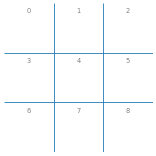

Available actions: [0, 1, 2, 3, 4, 5, 6, 7, 8]


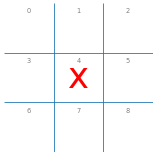

After X plays position 4: [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' ']
Available actions after position 4: [0, 1, 2, 3, 5, 6, 7, 8]


In [ ]:
board = empty_board()
print('Empty board:', board)
show_board(board)
print('Available actions:', actions(board))

board_after_x = result(board, 'x', 4)
show_board(board_after_x)
print('After X plays position 4:', board_after_x)
print('Available actions after position 4:', actions(board_after_x))

The example below checks the model functions, the X-first utility convention, invalid actions, and malformed boards. It also confirms that `result()` leaves its input state unchanged.

In [ ]:
import numpy as np

empty = empty_board()
assert len(empty) == 9 and empty == [' '] * 9
assert actions(empty) == list(range(9))
center = result(empty, 'x', 4)
assert empty[4] == ' ' and center[4] == 'x'
assert actions(center) == [0, 1, 2, 3, 5, 6, 7, 8]
assert check_board(center) == 'n' and not terminal(center)

x_win = ['x', 'x', 'x', ' ', 'o', ' ', ' ', ' ', 'o']
draw = ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', 'x']
assert check_board(x_win) == 'x' and terminal(x_win)
assert utility(x_win) == 1 and utility(x_win, 'o') == -1
assert check_board(draw) == 'd' and utility(draw) == 0
assert utility(empty) is None

for invalid_state in ([' '] * 8, ['?'] + [' '] * 8):
    try:
        check_board(invalid_state)
    except ValueError:
        pass
    else:
        raise AssertionError('check_board must reject malformed boards')

for invalid_action in (4, -1, 9, 1.5, '4'):
    try:
        result(center, 'o', invalid_action)
    except ValueError:
        pass
    else:
        raise AssertionError(f'result accepted invalid action {invalid_action!r}')

print('All model checks passed: empty board, actions, transition, terminal/utility, and invalid input.')

All model checks passed: empty board, actions, transition, terminal/utility, and invalid input.


In [ ]:
board = empty_board()
board[0] = 'x'; board[3] = 'x'; board[6] = 'x'; board[1] = 'o'; board[4] = 'o'  
display(board)

['x', 'o', ' ', 'x', 'o', ' ', 'x', ' ', ' ']

In [ ]:
show_board_text(board)

[['x' 'o' ' ']
 ['x' 'o' ' ']
 ['x' ' ' ' ']]


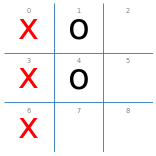

In [ ]:
show_board(board)

In [ ]:
actions(board)

[2, 5, 7, 8]

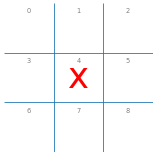

In [ ]:
board2 = empty_board()
board2 = result(board2, 'x', 4)
show_board(board2)

In [ ]:
print(terminal(board))
print(terminal(board2))

True
False


### Terminal state and utility examples

In [ ]:
x_win_board = ['x', 'x', 'x', ' ', 'o', ' ', ' ', ' ', 'o']
print('check_board(x_win_board):', check_board(x_win_board))
print("utility(X view):", utility(x_win_board, 'x'))
print("utility(O view):", utility(x_win_board, 'o'))
print("utility(empty board):", utility(empty_board(), 'x'))

check_board(x_win_board): x
utility(X view): 1
utility(O view): -1
utility(empty board): None


## Experiments


### Baseline: Randomized Player

A completely randomized player agent can be used as a weak baseline. A simple random agent and a the game environment
are implemented in [tictactoe.py](tictactoe.py) as `random_player()` and `play()`, respectively.

In [ ]:
from tictactoe import random_player, play 

### Random vs. Random

Run 1,000 games with X moving first, as in the notebook environment. The fixed NumPy seed makes the reported baseline reproducible.

In [ ]:
import numpy as np

np.random.seed(20261108)
number_of_games = 1000
ttt_results = play(random_player, random_player, N=number_of_games)
assert sum(ttt_results.values()) == number_of_games

print(f"Games: {number_of_games}")
for key, label in (("x", "X wins"), ("o", "O wins"), ("d", "Draws")):
    print(f"{label}: {ttt_results[key]} ({ttt_results[key] / number_of_games:.1%})")

print('\n| Result | Games | Rate |')
print('|---|---:|---:|')
for key, label in (("x", "X wins"), ("o", "O wins"), ("d", "Draws")):
    print(f"| {label} | {ttt_results[key]} | {ttt_results[key] / number_of_games:.1%} |")
print(f"| Total | {sum(ttt_results.values())} | {sum(ttt_results.values()) / number_of_games:.1%} |")

Games: 1000
X wins: 568 (56.8%)
O wins: 300 (30.0%)
Draws: 132 (13.2%)

| Result | Games | Rate |
|---|---:|---:|
| X wins | 568 | 56.8% |
| O wins | 300 | 30.0% |
| Draws | 132 | 13.2% |
| Total | 1000 | 100.0% |


_Observation from this run:_ X moves first in every game and won 568 (56.8%), versus 300 O wins (30.0%); this sample favors the first player. There were 132 draws (13.2%), so draws occur but were not the most common outcome. Random action choices make unseeded runs vary; seed `20261108` makes this particular run reproducible. One sample is not a statistical significance test.

### Combined Random-Agent baseline

| Game | Games | Player 1 / X wins | Player -1 / O wins | Draws | Starting-player protocol |
|---|---:|---:|---:|---:|---|
| Tic-Tac-Toe | 1,000 | 568 (56.8%) | 300 (30.0%) | 132 (13.2%) | X always starts (notebook `play`) |
| Connect 4 | 1,000 | 510 (51.0%) | 487 (48.7%) | 3 (0.3%) | Start side alternated 500/500; first player won 546 (54.6%) |

Both experiments compare identical random policies; they are baselines, not comparisons between agent implementations. Tic-Tac-Toe's fixed X-first protocol exposes the first-move advantage directly. Connect 4 balances the player labels by alternating the starting side. A single seeded sample illustrates the behavior but is not a statistical significance test.

### Discussion 6 — Vì sao không gian tìm kiếm Connect 4 và Dots and Boxes tăng nhanh? (Đặng Thái Tú)

Trò chơi nhiều lượt với nhiều lựa chọn mỗi lượt tạo cây tìm kiếm có số nhánh tăng theo cấp số nhân hoặc theo hoán vị của các hành động. Với **Connect 4 chuẩn 6×7**, có 42 ô và tối đa bảy cột hợp lệ ở mỗi lượt. Cận trên rất rộng khi bỏ qua trọng lực, cột đầy và thắng sớm là `3**42` cách gán ô; số đường đi trong cây tìm kiếm không cắt tỉa có cận trên `sum(7**d for d in range(43))`. Mã `connect4_core.actions()` thực tế chỉ trả những cột còn trống, `terminal()` kết thúc khi thắng hoặc hết ô, nên số trạng thái hợp lệ nhỏ hơn cận trên.

Với **Dots and Boxes** trên lưới 4×4 *điểm*, có 12 cạnh ngang và 12 cạnh dọc (24 cạnh). Chỉ xét cạnh đã vẽ đã có đến `2**24` tập hợp, còn số thứ tự chọn lần lượt đủ 24 cạnh lên đến `24!`. Chủ sở hữu các ô và luật đi thêm khi khép ô làm trạng thái phải chứa thêm thông tin ngoài tập cạnh. Đây là phân tích *giới hạn tổ hợp theo luật chơi*; notebook Dots and Boxes của repository chưa triển khai đầy đủ để đo số nút thực nghiệm.

Kết quả Task 3 Connect 4 trong `assignment_connect4.ipynb` xác nhận xu hướng thực tế: Alpha-Beta hoàn tất bàn trống 4×4 với 62.889 nút, nhưng không xong trong giới hạn 500.000 nút ở bàn trống 4×5. Vì vậy, cần cắt tỉa Alpha-Beta, sắp xếp nước và cắt độ sâu bằng heuristic để đáp ứng thời gian xử lý.

In [ ]:
# Tính cận trên lý thuyết cho Discussion 6; không khẳng định tất cả là trạng thái hợp lệ.
import math

ttt_board_assignments = 3 ** 9
connect4_board_assignments = 3 ** 42
connect4_tree_nodes_upper = sum(7 ** d for d in range(43))
dots_rows, dots_cols = 4, 4
dots_edges = dots_rows * (dots_cols - 1) + dots_cols * (dots_rows - 1)
dots_edge_subsets = 2 ** dots_edges
dots_edge_orders = math.factorial(dots_edges)

assert dots_edges == 24
print(f'Tic-Tac-Toe, mọi cách gán 9 ô: {ttt_board_assignments:,}')
print(f'Connect 4, mọi cách gán 42 ô (cận trên rất rộng): {connect4_board_assignments:,}')
print(f'Connect 4, cây 7 nhánh/42 lượt (cận trên rất rộng): {connect4_tree_nodes_upper:.4e}')
print(f'Dots and Boxes, lưới điểm 4×4 có {dots_edges} cạnh.')
print(f'Dots and Boxes, số tập hợp cạnh: {dots_edge_subsets:,}')
print(f'Dots and Boxes, số thứ tự chọn cạnh: {dots_edge_orders:,} (~{dots_edge_orders:.4e})')
print('Lưu ý: đây là các cận trên tổ hợp; không phải kết quả benchmark Dots and Boxes.')